# 02 — Post-traitement du PINN

Affichage des historiques de pertes et des champs prédits par le réseau.

Une faible perte d'entraînement ne constitue pas, à elle seule, une validation physique. Les résultats doivent être comparés aux sorties OpenFOAM indépendantes.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))
print('Répertoire du projet :', ROOT)

Répertoire du projet : /home/ludodo/SINN


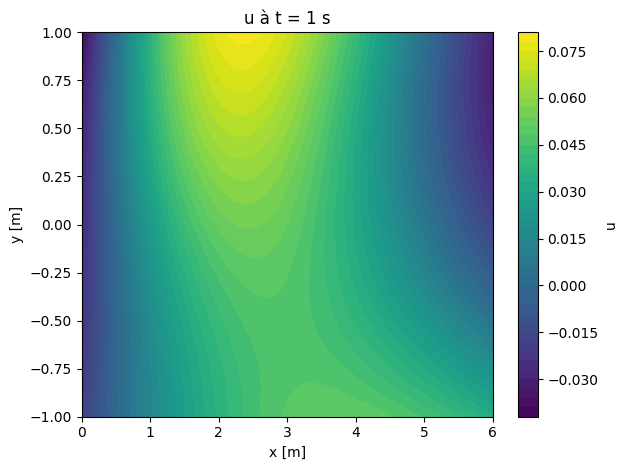

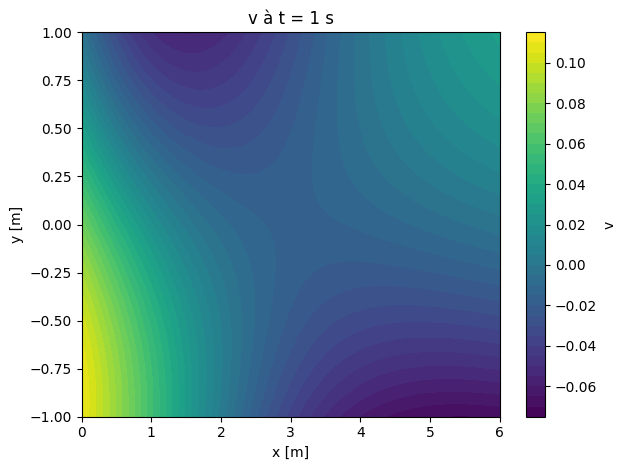

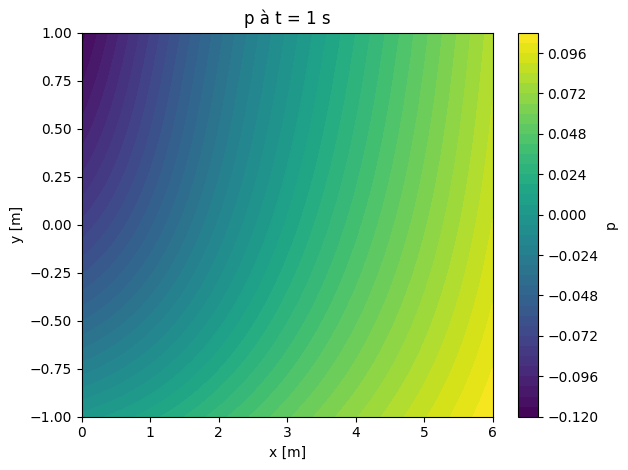

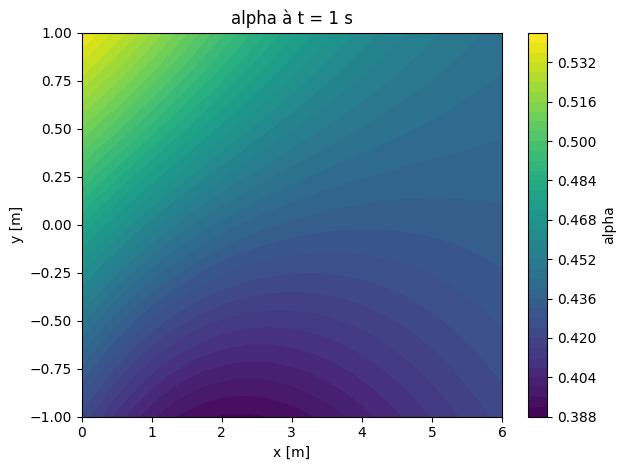

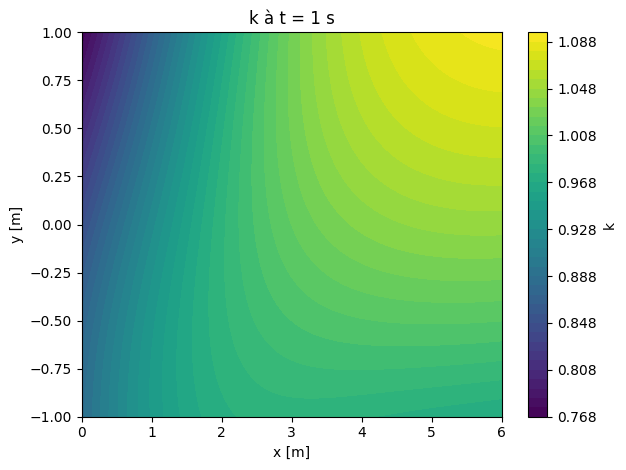

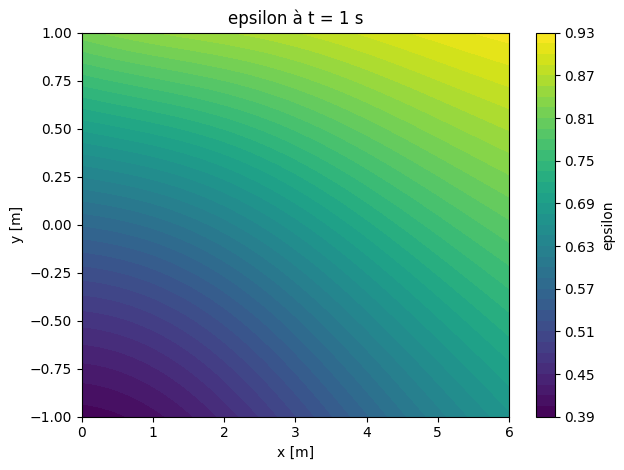

In [2]:
from visualization import plot_fields

# Choisir un instant compris entre t_min et t_max.
checkpoint = ROOT / 'models' / 'sinn_2026-10-15_09-59-19.pt'
plot_fields(t=1.0, checkpoint=str(checkpoint))

## Comparaison avec OpenFOAM

Avant de comparer les champs, harmoniser les unités, le repère, la définition de la pression et la convention de normale à l'interface. Examiner notamment alpha, la vitesse, la pression et les forces sur les parois.

In [3]:
from visualization import animate_comparison
from model import generate_sinn_npz

In [5]:
generate_sinn_npz(
    openfoam_npz=ROOT / "data" / "sloshing_data.npz",
    checkpoint= ROOT / "models" / "sinn_2026-10-15_09-59-19.pt",
    config=ROOT / "models" / "config_2026-10-15_09-59-19.json",
    output_npz=ROOT / "data/sinn_output.npz"
)

[SINN 1/100] t = 0.2 s
[SINN 2/100] t = 0.4 s
[SINN 3/100] t = 0.6 s
[SINN 4/100] t = 0.8 s
[SINN 5/100] t = 1 s
[SINN 6/100] t = 1.2 s
[SINN 7/100] t = 1.4 s
[SINN 8/100] t = 1.6 s
[SINN 9/100] t = 1.8 s
[SINN 10/100] t = 2 s
[SINN 11/100] t = 2.2 s
[SINN 12/100] t = 2.4 s
[SINN 13/100] t = 2.6 s
[SINN 14/100] t = 2.8 s
[SINN 15/100] t = 3 s
[SINN 16/100] t = 3.2 s
[SINN 17/100] t = 3.4 s
[SINN 18/100] t = 3.6 s
[SINN 19/100] t = 3.8 s
[SINN 20/100] t = 4 s
[SINN 21/100] t = 4.2 s
[SINN 22/100] t = 4.4 s
[SINN 23/100] t = 4.6 s
[SINN 24/100] t = 4.8 s
[SINN 25/100] t = 5 s
[SINN 26/100] t = 5.2 s
[SINN 27/100] t = 5.4 s
[SINN 28/100] t = 5.6 s
[SINN 29/100] t = 5.8 s
[SINN 30/100] t = 6 s
[SINN 31/100] t = 6.2 s
[SINN 32/100] t = 6.4 s
[SINN 33/100] t = 6.6 s
[SINN 34/100] t = 6.8 s
[SINN 35/100] t = 7 s
[SINN 36/100] t = 7.2 s
[SINN 37/100] t = 7.4 s
[SINN 38/100] t = 7.6 s
[SINN 39/100] t = 7.8 s
[SINN 40/100] t = 8 s
[SINN 41/100] t = 8.2 s
[SINN 42/100] t = 8.4 s
[SINN 43/100] t =

PosixPath('/home/ludodo/SINN/data/sinn_output.npz')

In [7]:
animation, fig = animate_comparison(
    str(ROOT / "data" / "sloshing_data.npz"),
    str(ROOT / "data" / "sinn_output.npz")
    )